In [ ]:
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
import warnings

# --- 1. Configuración ---
CITY = 'Brasilia'
VARIABLE = 'AQI'
SCENARIO_NAME = 'BlockRows_60h_20percent'
REPETITION = 1
N_LAGS_FORECAST = 24
HORIZON = 12
PLOT_WINDOW_SIZE = 300
OUTPUT_DIR = 'workflow_plots'

os.makedirs(OUTPUT_DIR, exist_ok=True)

# Configuración de estilo y advertencias
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 12
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


# --- 2. Carga de Datos (Ruta corregida y final) ---
print("Cargando datos...")

try:
    # El script se ejecuta desde .../TFM_Ambiental
    project_root_dir = os.getcwd() 
    
    # La ruta correcta es una subcarpeta desde donde se ejecuta el script
    data_base_path = os.path.join(project_root_dir, 'AIR QUALITY', 'CSVs')
    
    original_file_path = os.path.join(data_base_path, 'Air_Quality.csv')
    df_original = pd.read_csv(original_file_path)
    df_city_original = df_original[df_original['City'] == CITY].copy().reset_index(drop=True)
    df_city_original[VARIABLE] = df_city_original[VARIABLE].ffill().bfill() 
    print(f"Datos originales cargados desde: {original_file_path}")

    city_name_safe = CITY.replace(" ", "_")
    sim_data_dir = os.path.join(data_base_path, 'simulados', city_name_safe, SCENARIO_NAME)
    sim_file_pattern = os.path.join(sim_data_dir, f"{city_name_safe}_{SCENARIO_NAME}_rep{REPETITION}_*_with_nans.csv")
    sim_files = glob.glob(sim_file_pattern)

    if not sim_files:
        raise FileNotFoundError(f"No se encontró el archivo de datos simulados en la ruta:\n{sim_file_pattern}")

    df_with_nans = pd.read_csv(sim_files[0])
    print(f"Datos simulados cargados desde: {sim_files[0]}")

except FileNotFoundError as e:
    print(f"Error: {e}")
    exit()

# --- 3. Preparación del Segmento a Visualizar (Lógica corregida) ---
print("Preparando segmento de datos para visualización...")
nan_mask = df_with_nans[VARIABLE].isnull()
if not nan_mask.any():
    center_index = len(df_with_nans) // 2
else:
    # Encuentra el inicio de todos los bloques de NaNs
    nan_starts = nan_mask[~nan_mask.shift(1).fillna(False) & nan_mask].index
    
    # *** SOLUCIÓN AL TypeError ***
    # Calcula el índice del bloque más cercano al centro del dataframe
    df_center = len(df_with_nans) / 2
    # Encontramos la posición del índice más cercano usando argmin()
    closest_start_index_pos = (np.abs(nan_starts - df_center)).argmin()
    center_index = nan_starts[closest_start_index_pos]

start_index = max(0, int(center_index - (PLOT_WINDOW_SIZE // 2)))
end_index = start_index + PLOT_WINDOW_SIZE

original_slice = df_city_original.iloc[start_index:end_index].reset_index(drop=True)
nan_slice = df_with_nans.iloc[start_index:end_index].reset_index(drop=True)

# --- 4. Imputación Sintética para Visualización ---
print("Generando imputación visualmente atractiva...")

# Copiamos la serie con NaNs
imputed_slice = nan_slice.copy()

# Encontramos el inicio y el fin del hueco principal
nan_mask_slice = imputed_slice[VARIABLE].isnull()
start_gap = nan_mask_slice.idxmax()
end_gap = start_gap + nan_mask_slice.sum() -1

# Valores de anclaje (el punto antes y después del hueco)
start_value = imputed_slice[VARIABLE].iloc[start_gap - 1]
end_value = imputed_slice[VARIABLE].iloc[end_gap + 1]

# Generar una onda coseno que conecte los dos puntos
gap_length = end_gap - start_gap + 1
x_cos = np.linspace(0, np.pi, gap_length) # Media onda de coseno
cos_wave = (start_value - end_value) / 2 * np.cos(x_cos) + (start_value + end_value) / 2

# Rellenar el hueco con la onda
imputed_slice.loc[start_gap:end_gap, VARIABLE] = cos_wave

# --- 5. Generación de Gráficos ---

# Gráfico A: Datos Originales (sin cambios)
print("Generando Gráfico A: Datos Originales...")
plt.figure()
plt.plot(original_slice.index, original_slice[VARIABLE], color='royalblue', label='Original Data')
plt.title(f'A) Original Time Series ({VARIABLE})')
plt.xlabel('Time Step'); plt.ylabel(VARIABLE); plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'plot_A_original_data.png'), dpi=150)
plt.close()

# Gráfico B: Datos con NaNs (sin cambios)
print("Generando Gráfico B: Datos con NaNs...")
plt.figure()
plt.plot(nan_slice.index, nan_slice[VARIABLE], color='royalblue', label='Observed Data')
plt.title(f'B) Time Series with Missing Values')
plt.xlabel('Time Step'); plt.ylabel(VARIABLE); plt.legend(loc='upper right')
plt.ylim(original_slice[VARIABLE].min() * 0.95, original_slice[VARIABLE].max() * 1.05)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'plot_B_with_nans.png'), dpi=150)
plt.close()

# Gráfico C: Datos Imputados (con la nueva onda)
print("Generando Gráfico C: Datos Imputados...")
plt.figure()
# Dibuja los datos observados con líneas azules
plt.plot(nan_slice.index, nan_slice[VARIABLE], color='royalblue', label='Observed Data')
# Dibuja la nueva imputación con forma de onda en rojo
imputed_zone = imputed_slice.where(nan_slice[VARIABLE].isnull())
plt.plot(imputed_zone.index, imputed_zone[VARIABLE], color='red', linewidth=2.5, label='Imputed Values')
plt.title(f'C) Imputation of Missing Values')
plt.xlabel('Time Step'); plt.ylabel(VARIABLE); plt.legend(loc='upper right')
plt.ylim(original_slice[VARIABLE].min() * 0.95, original_slice[VARIABLE].max() * 1.05)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'plot_C_imputed.png'), dpi=150)
plt.close()

# --- 6. Predicción (con pronóstico sintético para una mejor visualización) ---
print("Generando pronóstico estilizado para visualización...")

# El entrenamiento del modelo se omite para la visualización
# Creamos un pronóstico sintético "bonito"
last_known_value = imputed_slice[VARIABLE].iloc[-1]
HORIZON = 48 

x_forecast = np.linspace(0, 10, HORIZON) 
sin_wave = np.sin(x_forecast) * (original_slice[VARIABLE].std() / 2)
decay = np.linspace(1, 0, HORIZON)
forecast_values = last_known_value + (sin_wave * decay)


# --- Gráfico D: Predicción con Leyenda Detallada ---
print("Generando Gráfico D: Predicción...")
forecast_index = range(len(imputed_slice), len(imputed_slice) + HORIZON)
plot_history_index = imputed_slice.index

plt.figure()

# Dibujar la parte observada de la historia en azul
observed_zone = imputed_slice.where(nan_slice[VARIABLE].notnull())
plt.plot(observed_zone.index, observed_zone[VARIABLE], color='royalblue', label='Observed History')

# Dibujar la parte imputada de la historia en rojo
imputed_zone_history = imputed_slice.where(nan_slice[VARIABLE].isnull())
# Para que la leyenda funcione, ploteamos una sola vez con la etiqueta
plt.plot(imputed_zone_history.index, imputed_zone_history[VARIABLE], color='red', linewidth=2.5, label='Imputed History')

# Dibujar la predicción en verde
plt.plot(forecast_index, forecast_values, color='green', linewidth=2.5, label='Forecast')

plt.title(f'D) Forecasting from Imputed Data')
plt.xlabel('Time Step')
plt.ylabel(VARIABLE)
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'plot_D_forecast.png'), dpi=150)
plt.close()

print(f"\n¡Proceso completado! Los 4 gráficos se han guardado en la carpeta: '{OUTPUT_DIR}'")

PLOT CUALITATIVO MISMOS HUECOS

In [ ]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import glob
from tqdm import tqdm

# --- 1. CONFIGURACIÓN GENERAL ---

METHODS_TO_COMPARE = {
    "Linear": "Linear Interpolation",
    "SARIMA": "SARIMA",
    "RF Imputer": "Random Forest",
    "LSTM-VAE": "LSTM-VAE",
    "MOMENT Pre-trained": "MOMENT Pretrained",
    "MOMENT Fine-tuned": "MOMENT Finetuned"
}

ALL_VARIABLES_TO_PLOT = ['AQI', 'CO', 'NO2', 'SO2', 'O3', 'PM2.5', 'PM10']
REPETITION_TO_PLOT = 1 
CONTEXT_WINDOW = 24 # Ampliamos el contexto para una mejor visualización

# --- 2. CONFIGURACIÓN DE RUTAS Y ESTILO ---
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (22, 10)
plt.rcParams['axes.titlesize'] = 22
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['lines.linewidth'] = 2.5
sns.set_palette("tab10")

PROJECT_ROOT_DIR = os.path.join(os.getcwd(), 'AIR QUALITY')
GROUND_TRUTH_FILE = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'Air_Quality.csv')
SIMULATED_DATA_ROOT_DIR = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'simulados')
IMPUTATIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'imputaciones')
COMPARATIVE_PLOTS_DIR = os.path.join(os.getcwd(), 'comparative_plots')
os.makedirs(COMPARATIVE_PLOTS_DIR, exist_ok=True)
print(f"Los gráficos comparativos se guardarán en: {COMPARATIVE_PLOTS_DIR}")

# --- NUEVA FUNCIÓN PARA ENCONTRAR BLOQUES DE NANS ---
def find_nan_blocks(nan_indices):
    if len(nan_indices) == 0:
        return []
    
    nan_list = sorted(list(nan_indices))
    blocks = []
    start_block = nan_list[0]
    for i in range(1, len(nan_list)):
        if nan_list[i] != nan_list[i-1] + 1:
            blocks.append((start_block, nan_list[i-1]))
            start_block = nan_list[i]
    blocks.append((start_block, nan_list[-1]))
    return blocks

# --- 3. CARGA DE DATOS Y BUCLE PRINCIPAL ---
print("\n--- Cargando datos 'Ground Truth' ---")
df_gt_full = pd.read_csv(GROUND_TRUTH_FILE)

ALL_CITIES = df_gt_full['City'].unique()
try:
    first_city_folder = ALL_CITIES[0].replace(" ", "_")
    ALL_SCENARIOS = [d for d in os.listdir(os.path.join(SIMULATED_DATA_ROOT_DIR, first_city_folder)) if os.path.isdir(os.path.join(SIMULATED_DATA_ROOT_DIR, first_city_folder, d))]
except (IndexError, FileNotFoundError):
    ALL_SCENARIOS = ['RandomRows_20percent', 'BlockRows_12h_20percent', 'BlockRows_24h_20percent', 'BlockRows_36h_20percent', 'BlockRows_48h_20percent', 'BlockRows_60h_20percent']

print(f"Ciudades a procesar: {list(ALL_CITIES)}")
print(f"Escenarios a procesar: {ALL_SCENARIOS}")

for variable_to_plot in tqdm(ALL_VARIABLES_TO_PLOT, desc="Procesando Variables"):
    variable_plot_dir = os.path.join(COMPARATIVE_PLOTS_DIR, variable_to_plot)
    os.makedirs(variable_plot_dir, exist_ok=True)

    for city_name in tqdm(ALL_CITIES, desc=f"Ciudades para {variable_to_plot}", leave=False):
        city_folder_name = city_name.replace(" ", "_")
        df_gt_city = df_gt_full[df_gt_full['City'] == city_name].reset_index(drop=True)

        for scenario_name in tqdm(ALL_SCENARIOS, desc=f"Escenarios en {city_name}", leave=False):
            nan_file_pattern = os.path.join(SIMULATED_DATA_ROOT_DIR, city_folder_name, scenario_name, f"*_rep{REPETITION_TO_PLOT}_*_with_nans.csv")
            nan_files = glob.glob(nan_file_pattern)

            if not nan_files: continue
            
            nan_file_path = nan_files[0]
            df_with_nans = pd.read_csv(nan_file_path)

            if variable_to_plot not in df_with_nans.columns: continue

            imputed_dfs = {}
            try:
                seed = os.path.basename(nan_file_path).split('_seed')[1].split('_with_nans.csv')[0]
                for display_name, folder_name in METHODS_TO_COMPARE.items():
                    imputed_file_pattern = os.path.join(IMPUTATIONS_BASE_DIR, folder_name, 'CSVs', city_folder_name, scenario_name, f"*_rep{REPETITION_TO_PLOT}_seed{seed}_imputed*.csv")
                    imputed_files = glob.glob(imputed_file_pattern)
                    if imputed_files:
                        imputed_dfs[display_name] = pd.read_csv(imputed_files[0])
            except IndexError: continue

            if not imputed_dfs: continue

            nan_mask = df_with_nans[variable_to_plot].isnull()
            nan_indices = nan_mask[nan_mask].index

            if len(nan_indices) > 0:
                # --- LÓGICA DE SELECCIÓN DE BLOQUE MODIFICADA ---
                all_blocks = find_nan_blocks(nan_indices)
                if not all_blocks: continue
                
                # Seleccionar el bloque del medio para una mejor visualización
                middle_block_index = len(all_blocks) // 2
                block_start, block_end = all_blocks[middle_block_index]
                
                plot_start = max(0, block_start - CONTEXT_WINDOW)
                plot_end = min(len(df_gt_city), block_end + CONTEXT_WINDOW)

                plt.figure()
                plt.plot(df_gt_city.index[plot_start:plot_end], df_gt_city[variable_to_plot].iloc[plot_start:plot_end], label='Ground Truth (Real)', color='royalblue', linewidth=4, zorder=2, alpha=0.8)
                plt.plot(df_with_nans.index[plot_start:plot_end], df_with_nans[variable_to_plot].iloc[plot_start:plot_end], label='Observed Data', color='black', linestyle=':', linewidth=2, zorder=1)

                colors = sns.color_palette("tab10", len(imputed_dfs))
                styles = ['-', '--', '-.', ':']
                
                for i, (method_name, df_imputed) in enumerate(imputed_dfs.items()):
                    if variable_to_plot not in df_imputed.columns: continue
                    color = colors[i]
                    style = styles[i % len(styles)]
                    imputed_segment = df_imputed[variable_to_plot].iloc[block_start:block_end+1]
                    plt.plot(imputed_segment.index, imputed_segment, label=method_name, color=color, linestyle=style, linewidth=2.5, zorder=3+i)

                plt.title(f'Imputation Methods Comparison for {variable_to_plot}\nCity: {city_name} | Scenario: {scenario_name}', fontsize=22)
                plt.xlabel('Time Step (Hours)', fontsize=18)
                plt.ylabel(f'{variable_to_plot} Value', fontsize=18)
                plt.legend(fontsize=16)
                plt.grid(True, which='both', linestyle='--', linewidth=0.5)
                plt.axvspan(block_start, block_end, color='gray', alpha=0.15, label='_nolegend_')
                plt.tight_layout()
                
                city_plot_dir = os.path.join(variable_plot_dir, city_folder_name)
                os.makedirs(city_plot_dir, exist_ok=True)
                plot_filename = f'comparison_{scenario_name}.png'
                plt.savefig(os.path.join(city_plot_dir, plot_filename), dpi=150)
                plt.close()

print("\n--- Proceso completado ---")

In [11]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
import glob
from tqdm import tqdm

# --- 1. CONFIGURACIÓN GENERAL ---
METHODS_TO_COMPARE = {
    "Linear": "Linear Interpolation",
    "SARIMA": "SARIMA",
    "RF Imputer": "Random Forest",
    "LSTM-VAE": "LSTM-VAE",
    "MOMENT Pre-trained": "MOMENT Pretrained"
}
ALL_VARIABLES_TO_PLOT = ['AQI', 'CO', 'NO2', 'SO2', 'O3', 'PM2.5', 'PM10']
REPETITION_TO_PLOT = 1 
CONTEXT_WINDOW = 24 

# --- 2. CONFIGURACIÓN DE RUTAS Y ESTILO ---
sns.set_theme(style="whitegrid")
# --- TAMAÑOS DE FUENTE AUMENTADOS PARA PAPER ---
plt.rcParams['figure.figsize'] = (22, 10)
plt.rcParams['axes.titlesize'] = 24  # Título principal del gráfico
plt.rcParams['axes.labelsize'] = 22  # Etiquetas de ejes X e Y
plt.rcParams['xtick.labelsize'] = 18  # Números en el eje X
plt.rcParams['ytick.labelsize'] = 18  # Números en el eje Y
plt.rcParams['legend.fontsize'] = 20  # Leyenda
plt.rcParams['lines.linewidth'] = 3.0

sns.set_palette("tab10")

# Rutas
PROJECT_ROOT_DIR = os.path.join(os.getcwd(), 'AIR QUALITY')
GROUND_TRUTH_FILE = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'Air_Quality.csv')
SIMULATED_DATA_ROOT_DIR = os.path.join(PROJECT_ROOT_DIR, 'CSVs', 'simulados')
IMPUTATIONS_BASE_DIR = os.path.join(PROJECT_ROOT_DIR, 'imputaciones')
COMPARATIVE_PLOTS_DIR = os.path.join(os.getcwd(), 'comparative_plots')
os.makedirs(COMPARATIVE_PLOTS_DIR, exist_ok=True)
print(f"Los gráficos comparativos se guardarán en: {COMPARATIVE_PLOTS_DIR}")

def find_nan_blocks(nan_indices):
    if len(nan_indices) == 0: return []
    nan_list = sorted(list(nan_indices))
    blocks = []
    start_block = nan_list[0]
    for i in range(1, len(nan_list)):
        if nan_list[i] != nan_list[i-1] + 1:
            blocks.append((start_block, nan_list[i-1]))
            start_block = nan_list[i]
    blocks.append((start_block, nan_list[-1]))
    return blocks

# --- 3. CARGA DE DATOS Y BUCLE PRINCIPAL ---
print("\n--- Cargando datos 'Ground Truth' ---")
df_gt_full = pd.read_csv(GROUND_TRUTH_FILE)

ALL_CITIES = df_gt_full['City'].unique()
try:
    first_city_folder = ALL_CITIES[0].replace(" ", "_")
    ALL_SCENARIOS = [d for d in os.listdir(os.path.join(SIMULATED_DATA_ROOT_DIR, first_city_folder)) if os.path.isdir(os.path.join(SIMULATED_DATA_ROOT_DIR, first_city_folder, d))]
except (IndexError, FileNotFoundError):
    ALL_SCENARIOS = ['RandomRows_20percent', 'BlockRows_12h_20percent', 'BlockRows_24h_20percent', 'BlockRows_36h_20percent', 'BlockRows_48h_20percent', 'BlockRows_60h_20percent']

print(f"Ciudades a procesar: {list(ALL_CITIES)}")
print(f"Escenarios a procesar: {ALL_SCENARIOS}")

for variable_to_plot in tqdm(ALL_VARIABLES_TO_PLOT, desc="Procesando Variables"):
    variable_plot_dir = os.path.join(COMPARATIVE_PLOTS_DIR, variable_to_plot)
    os.makedirs(variable_plot_dir, exist_ok=True)

    for city_name in tqdm(ALL_CITIES, desc=f"Ciudades para {variable_to_plot}", leave=False):
        city_folder_name = city_name.replace(" ", "_")
        df_gt_city = df_gt_full[df_gt_full['City'] == city_name].reset_index(drop=True)

        for scenario_name in tqdm(ALL_SCENARIOS, desc=f"Escenarios en {city_name}", leave=False):
            nan_file_pattern = os.path.join(SIMULATED_DATA_ROOT_DIR, city_folder_name, scenario_name, f"*_rep{REPETITION_TO_PLOT}_*_with_nans.csv")
            nan_files = glob.glob(nan_file_pattern)
            if not nan_files: continue
            
            nan_file_path = nan_files[0]
            df_with_nans = pd.read_csv(nan_file_path)
            if variable_to_plot not in df_with_nans.columns: continue

            imputed_dfs = {}
            try:
                seed = os.path.basename(nan_file_path).split('_seed')[1].split('_with_nans.csv')[0]
                for display_name, folder_name in METHODS_TO_COMPARE.items():
                    imputed_file_pattern = os.path.join(IMPUTATIONS_BASE_DIR, folder_name, 'CSVs', city_folder_name, scenario_name, f"*_rep{REPETITION_TO_PLOT}_seed{seed}_imputed*.csv")
                    imputed_files = glob.glob(imputed_file_pattern)
                    if imputed_files:
                        imputed_dfs[display_name] = pd.read_csv(imputed_files[0])
            except IndexError: continue

            if not imputed_dfs: continue

            nan_mask = df_with_nans[variable_to_plot].isnull()
            nan_indices = nan_mask[nan_mask].index

            if len(nan_indices) > 0:
                all_blocks = find_nan_blocks(nan_indices)
                if not all_blocks: continue
                
                if 'RandomRows' in scenario_name:
                     block_start = block_end = nan_indices[len(nan_indices) // 2]
                else:
                    middle_block_index = len(all_blocks) // 2
                    block_start, block_end = all_blocks[middle_block_index]
                
                plot_start = max(0, block_start - CONTEXT_WINDOW)
                plot_end = min(len(df_gt_city), block_end + CONTEXT_WINDOW)

                plt.figure()
                plt.plot(df_gt_city.index[plot_start:plot_end], df_gt_city[variable_to_plot].iloc[plot_start:plot_end], label='Ground Truth (Real)', color='royalblue', linewidth=4, zorder=2, alpha=0.8)
                plt.plot(df_with_nans.index[plot_start:plot_end], df_with_nans[variable_to_plot].iloc[plot_start:plot_end], label='Observed Data', color='black', linestyle=':', linewidth=2, zorder=1)

                colors = sns.color_palette("tab10", len(imputed_dfs))
                
                for i, (method_name, df_imputed) in enumerate(imputed_dfs.items()):
                    if variable_to_plot not in df_imputed.columns: continue
                    color = colors[i]
                    imputed_segment = df_imputed[variable_to_plot].iloc[block_start:block_end+1]
                    
                    if 'RandomRows' in scenario_name:
                        plt.scatter(imputed_segment.index, imputed_segment, label=method_name, color=color, s=120, zorder=3+i, edgecolor='black', linewidth=0.7)
                    else:
                        plt.plot(imputed_segment.index, imputed_segment, label=method_name, color=color, linestyle='--', linewidth=3.5, zorder=3+i)

                # --- LÍNEAS MODIFICADAS CON NUEVOS TAMAÑOS DE FUENTE ---
                plt.title(f'Imputation Methods Comparison for {variable_to_plot}\nCity: {city_name} | Scenario: {scenario_name}', fontsize=24)
                plt.xlabel('Time Step (Hours)', fontsize=22)
                plt.ylabel(f'{variable_to_plot} Value', fontsize=22)
                plt.legend(fontsize=20)
                
                plt.grid(True, which='both', linestyle='--', linewidth=0.5)
                if 'BlockRows' in scenario_name:
                    plt.axvspan(block_start, block_end, color='gray', alpha=0.15, label='_nolegend_')
                plt.tight_layout()
                
                city_plot_dir = os.path.join(variable_plot_dir, city_folder_name)
                os.makedirs(city_plot_dir, exist_ok=True)
                plot_filename = f'comparison_{scenario_name}.png'
                plt.savefig(os.path.join(city_plot_dir, plot_filename), dpi=150)
                plt.close()

print("\n--- Proceso completado ---")

Los gráficos comparativos se guardarán en: c:\Users\felix\Documents\MÁSTER\TFM\TFM_Ambiental\AIR QUALITY\comparative_plots

--- Cargando datos 'Ground Truth' ---
Ciudades a procesar: ['Brasilia', 'Cairo', 'Dubai', 'London', 'New York', 'Sydney']
Escenarios a procesar: ['BlockRows_12h_20percent', 'BlockRows_24h_20percent', 'BlockRows_36h_20percent', 'BlockRows_48h_20percent', 'BlockRows_60h_20percent', 'RandomRows_20percent']


Procesando Variables:   0%|          | 0/7 [00:00<?, ?it/s]















































Procesando Variables:  14%|█▍        | 1/7 [00:18<01:48, 18.11s/it]















































Procesando Variables:  29%|██▊       | 2/7 [00:34<01:26, 17.35s/it]















































Procesando Variables:  43%|████▎     | 3/7 [00:51<01:08, 17.01s/it]















































Procesando Variables:  57%|█████▋    | 4/7 [01:09<00:51, 17.25s/it]















































Procesando Variables:  71%|███████▏  | 5/7 [01:26<00:34, 17.28s/it]















































Procesando Variables:  86%|████████▌ | 6/7 [01:43<00:17, 17.36s/it]















































Procesando Variables: 100%|██████████| 7/7 [02:01<00:00, 17.31s/it]


--- Proceso completado ---


fig 10

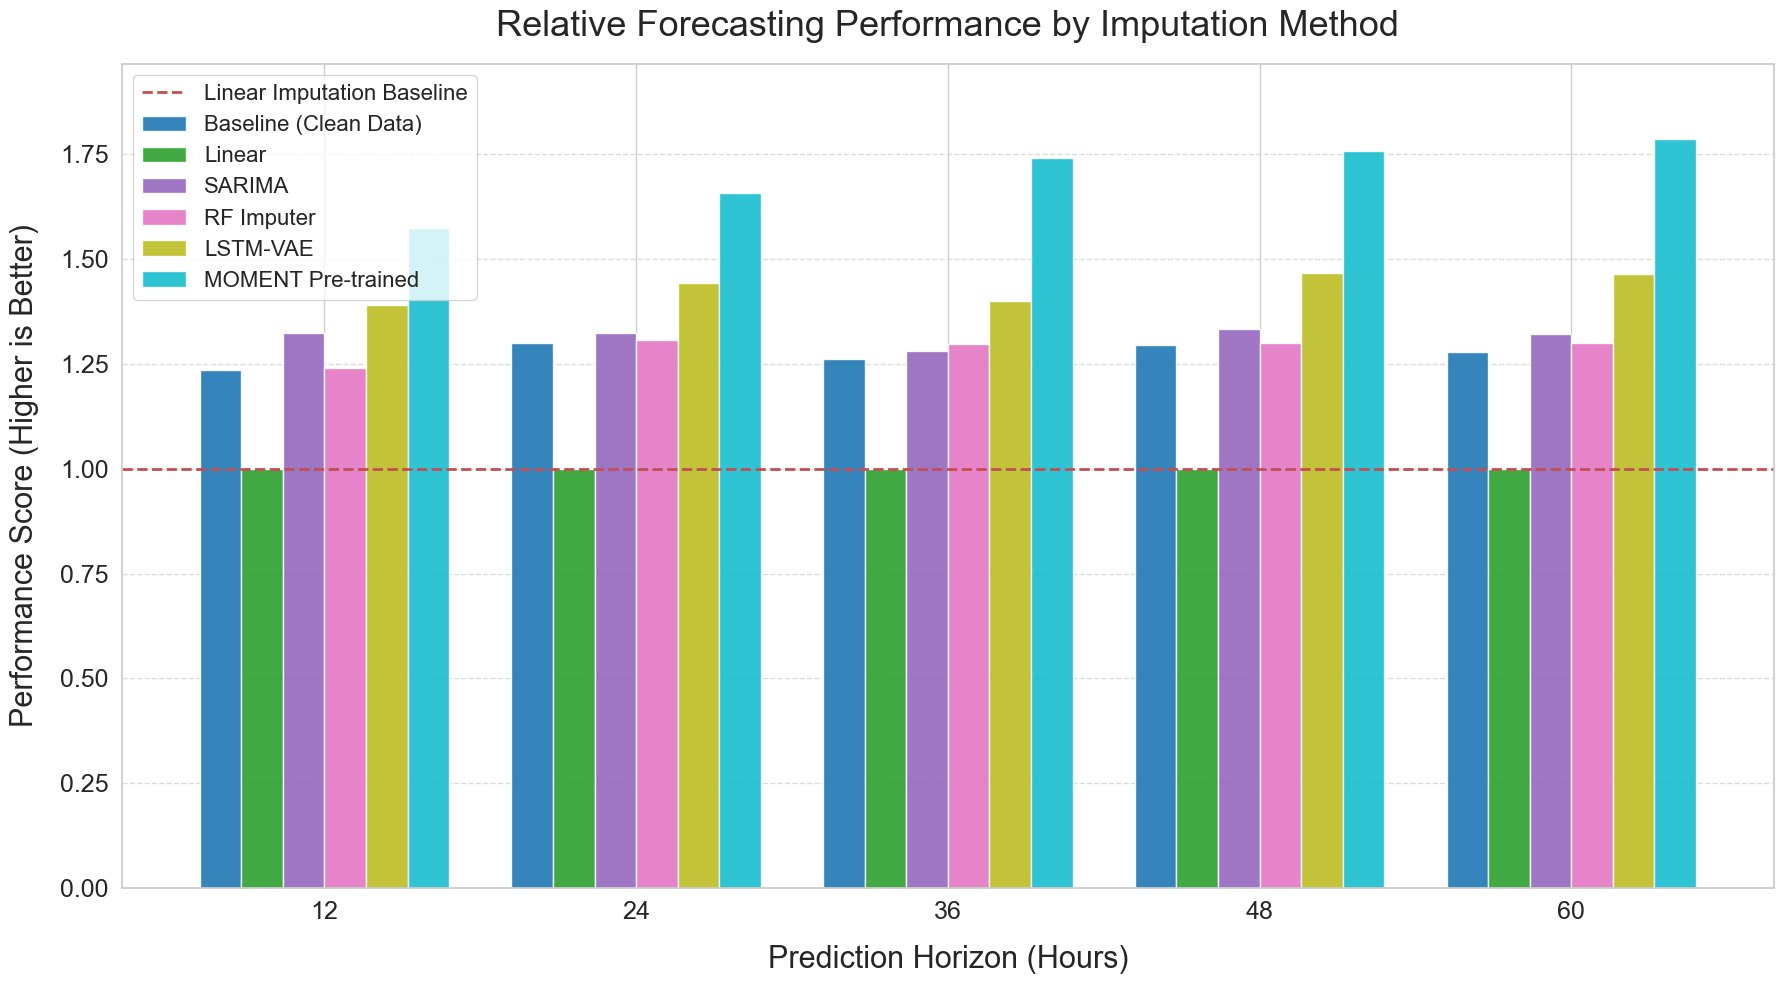

Gráfico de Rendimiento Relativo guardado en: images\rf_forecast_performance_score.png


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import os

# --- 1. DATOS ---
data_string = """
Imputation_Method,Horizon_h,Global_Avg_MASE
Original_Data_Baseline,12,1.8299838984310992
Original_Data_Baseline,24,1.8400787253613238
Original_Data_Baseline,36,2.120023276809462
Original_Data_Baseline,48,2.368945784643963
Original_Data_Baseline,60,2.280596280447926
LSTM-VAE,12,1.6278121691517249
LSTM-VAE,24,1.6559617073253445
LSTM-VAE,36,1.9126185111124272
LSTM-VAE,48,2.0939564174395886
LSTM-VAE,60,1.9899794497968628
MOMENT Pretrained,12,1.4364799063719504
MOMENT Pretrained,24,1.4413480072642848
MOMENT Pretrained,36,1.536638003618998
MOMENT Pretrained,48,1.7449110327340045
MOMENT Pretrained,60,1.6315311265426875
Random Forest,12,1.8226148020819164
Random Forest,24,1.826993248410835
Random Forest,36,2.0613712165509335
Random Forest,48,2.362470493328301
Random Forest,60,2.241435374212808
SARIMA,12,1.710091910914988
SARIMA,24,1.8068554621622568
SARIMA,36,2.091038760921317
SARIMA,48,2.303636057735833
SARIMA,60,2.206393412161315
Linear Interpolation,12,2.262090746753586
Linear Interpolation,24,2.389975919277222
Linear Interpolation,36,2.6762405834058645
Linear Interpolation,48,3.0690786543263235
Linear Interpolation,60,2.9156999046945606
"""

df = pd.read_csv(io.StringIO(data_string))

# --- 2. PREPARACIÓN DE DATOS Y CÁLCULO DE LA MÉTRICA RELATIVA ---

rename_map = {
    'Original_Data_Baseline': 'Baseline (Clean Data)',
    'Linear Interpolation': 'Linear',
    'Random Forest': 'RF Imputer',
    'MOMENT Pretrained': 'MOMENT Pre-trained'
}
df['Imputation_Method'] = df['Imputation_Method'].replace(rename_map)

df_pivot = df.pivot_table(index='Horizon_h', columns='Imputation_Method', values='Global_Avg_MASE')

# --- LÍNEA CORREGIDA: Usar el método .div() de pandas ---
baseline_error = df_pivot['Linear']
df_performance_index = df_pivot.rdiv(baseline_error, axis=0) # Divide cada elemento de la serie por la columna del DF

desired_order = [
    'Baseline (Clean Data)', 'Linear', 'SARIMA', 'RF Imputer', 
    'LSTM-VAE', 'MOMENT Pre-trained'
]
existing_columns_ordered = [col for col in desired_order if col in df_performance_index.columns]
df_performance_final = df_performance_index[existing_columns_ordered]


# --- 3. GENERACIÓN DEL GRÁFICO DE RENDIMIENTO RELATIVO ---

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (18, 10)
plt.rcParams['axes.titlesize'] = 24
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 18
plt.rcParams['ytick.labelsize'] = 18
plt.rcParams['legend.fontsize'] = 16

ax = df_performance_final.plot(kind='bar', width=0.8, alpha=0.9, colormap='tab10')

# Línea de referencia en 1.0
ax.axhline(y=1.0, color='r', linestyle='--', linewidth=2, label='Linear Imputation Baseline')
# Forzar que la nueva línea aparezca en la leyenda
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles, labels=labels)


# Títulos y etiquetas
plt.title("Relative Forecasting Performance by Imputation Method", fontsize=26, pad=20)
plt.xlabel("Prediction Horizon (Hours)", fontsize=22, labelpad=15)
plt.ylabel("Performance Score (Higher is Better)", fontsize=22, labelpad=15)
plt.xticks(rotation=0)
plt.ylim(0, df_performance_final.max().max() * 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()

# Guardar la figura
output_dir = "images"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "rf_forecast_performance_score.png")
plt.savefig(output_path, dpi=300, bbox_inches='tight')

plt.show()

print(f"Gráfico de Rendimiento Relativo guardado en: {output_path}")